In [1]:
import os
from huggingface_hub import login

try:
    from kaggle_secrets import UserSecretsClient
    secrets_client = UserSecretsClient()
    hf_token_raw = secrets_client.get_secret("HF")
except Exception:
    hf_token_raw = os.environ.get("HF_TOKEN", "")

os.environ["HF_TOKEN"] = hf_token_raw
if hf_token_raw:
    login(token=hf_token_raw)
    print("Hugging Face login successful.")
else:
    print("hf_token_raw not found in secrets/environment. Continuing unauthenticated.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0" 

import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 1
GPU 0: Tesla T4


In [3]:
%%writefile attention.py
import math
from typing import Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, max_seq_len: int, dropout: float = 0.1, attention_scale: float = None,
                 use_rope: bool = True, rope_base: float = 10000.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be evenly divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.gate_proj = nn.Linear(d_model, d_model, bias=False)

        self.use_rope = use_rope
        if use_rope:
            assert self.d_head % 2 == 0, "RoPE needs an even head dimension"
            inv_freq = 1.0 / (rope_base ** (torch.arange(0, self.d_head, 2, dtype=torch.float32) / self.d_head))
            angles = torch.arange(max_seq_len, dtype=torch.float32).unsqueeze(1) * inv_freq.unsqueeze(0)
            self.register_buffer("rope_cos", torch.cos(angles), persistent=False)
            self.register_buffer("rope_sin", torch.sin(angles), persistent=False)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
            persistent=False
        )

    def _apply_rope(self, x: torch.Tensor, start: int) -> torch.Tensor:
        T = x.size(2)
        cos = self.rope_cos[start:start + T].to(torch.float32)
        sin = self.rope_sin[start:start + T].to(torch.float32)
        x1, x2 = x[..., : self.d_head // 2].float(), x[..., self.d_head // 2:].float()
        out = torch.cat((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1)
        return out.to(x.dtype)

    def forward(
        self,
        x: torch.Tensor,
        cached_kv: Optional[Tuple[torch.Tensor, torch.Tensor]] = None,
        use_cache: bool = False,
        padding_mask: Optional[torch.Tensor] = None,
    ):
        B, T, C = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        cache_len = 0
        if cached_kv is not None:
            cache_len = cached_kv[0].size(2)

        if self.use_rope:
            q = self._apply_rope(q, cache_len)
            k = self._apply_rope(k, cache_len)

        if cached_kv is not None:
            cached_k, cached_v = cached_kv
            k = torch.cat([cached_k, k], dim=2)
            v = torch.cat([cached_v, v], dim=2)
        full_len = cache_len + T
        present = (k, v) if use_cache else None

        if padding_mask is None and cache_len == 0:
            output = F.scaled_dot_product_attention(
                q, k, v,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
                is_causal=True,
                scale=self.attention_scale,
            )
        else:
            scores = (q @ k.transpose(-2, -1)) * self.attention_scale

            mask = self.causal_mask[cache_len:full_len, :full_len]
            if padding_mask is not None:
                mask = mask.unsqueeze(0) & padding_mask.to(torch.bool).unsqueeze(1)
                mask = mask | ~mask.any(dim=-1, keepdim=True)
                mask = mask.unsqueeze(1)
            scores = scores.masked_fill(~mask, float("-inf"))

            attention_weights = F.softmax(scores, dim=-1)
            attention_weights = self.attn_dropout(attention_weights)

            output = attention_weights @ v

        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = output * torch.sigmoid(self.gate_proj(x))
        output = self.out_proj(output)
        output = self.resid_dropout(output)

        if use_cache:
            return output, present
        return output

Writing attention.py


In [4]:
%%writefile model_arch.py
import math
from dataclasses import dataclass
from typing import Optional, List, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.utils import ModelOutput
from attention import CausalSelfAttention

@dataclass
class LMConfig:
    vocab_size: int
    d_model: int = 560
    n_layers: int = 8
    n_heads: int = 8
    d_ff: int = 2240
    max_seq_len: int = 1024
    dropout: float = 0
    pos_emb_type: str = "rope"
    attention_scale: float = None
    norm_first: bool = True
    bos_token_id: int = None
    eos_token_id: int = None

@dataclass
class CausalLMOutput(ModelOutput):
    loss: Optional[torch.Tensor] = None
    logits: Optional[torch.Tensor] = None
    kv_cache: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None

def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model, dtype=torch.float32)
    pe[:, 0::2] = torch.sin(pos * div_term)
    pe[:, 1::2] = torch.cos(pos * div_term)
    return pe

class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = getattr(cfg, 'norm_first', True)
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            d_model=cfg.d_model,
            n_heads=cfg.n_heads,
            max_seq_len=cfg.max_seq_len,
            dropout=cfg.dropout,
            attention_scale=cfg.attention_scale,
            use_rope=(cfg.pos_emb_type == "rope")
        )
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x: torch.Tensor, cached_kv=None, use_cache: bool = False, padding_mask=None):
        if self.norm_first:
            attn_result = self.attn(self.ln1(x), cached_kv=cached_kv, use_cache=use_cache, padding_mask=padding_mask)
            if use_cache:
                attn_result, present = attn_result
            x = x + attn_result
            x = x + self.ffn(self.ln2(x))
        else:
            attn_result = self.attn(x, cached_kv=cached_kv, use_cache=use_cache, padding_mask=padding_mask)
            if use_cache:
                attn_result, present = attn_result
            x = self.ln1(x + attn_result)
            x = self.ln2(x + self.ffn(x))
        if use_cache:
            return x, present
        return x

class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)

        if cfg.pos_emb_type == "sinusoidal":
            pe = sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model)
            self.register_buffer("pos_emb", pe, persistent=False)

        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)

        self.head.weight = self.tok_emb.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.ones_(module.weight)
            torch.nn.init.zeros_(module.bias)

    def forward(self, input_ids: torch.Tensor = None, labels: torch.Tensor = None, idx: torch.Tensor = None,
                kv_cache: Optional[List[Tuple[torch.Tensor, torch.Tensor]]] = None,
                use_cache: bool = False,
                attention_mask: Optional[torch.Tensor] = None,
                last_token_only: bool = False):
        if idx is None:
            idx = input_ids
        assert idx is not None, "Either input_ids or idx must be provided"

        B, T = idx.shape
        cache_len = 0 if kv_cache is None else kv_cache[0][0].size(2)
        assert cache_len + T <= self.cfg.max_seq_len, \
            f"Seq length {cache_len + T} exceeds max sequence length {self.cfg.max_seq_len}"

        x = self.tok_emb(idx)
        if self.cfg.pos_emb_type == "sinusoidal":
            if attention_mask is None:
                x = x + self.pos_emb[cache_len:cache_len + T]
            else:
                position_ids = (attention_mask.long().cumsum(dim=-1) - 1).clamp(min=0)[:, -T:]
                x = x + self.pos_emb[position_ids]

        presents = [] if use_cache else None
        for i, block in enumerate(self.blocks):
            cached_kv = None if kv_cache is None else kv_cache[i]
            if use_cache:
                x, present = block(x, cached_kv=cached_kv, use_cache=True, padding_mask=attention_mask)
                presents.append(present)
            else:
                x = block(x, cached_kv=cached_kv, padding_mask=attention_mask)

        if last_token_only:
            x = x[:, -1:, :]
        x = self.ln_f(x)
        logits = self.head(x)

        loss = None
        if labels is not None:
            shifted_logits = logits[:, :-1, :].contiguous().view(-1, self.cfg.vocab_size)
            shifted_labels = labels[:, 1:].contiguous().view(-1)
            loss = F.cross_entropy(shifted_logits, shifted_labels, ignore_index=-100)
            return CausalLMOutput(loss=loss, logits=logits, kv_cache=presents)

        if use_cache:
            return logits, presents
        return logits

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int, temperature: float = 1.0, top_p: float = 1.0, eos_token_id: int = None, attention_mask: torch.Tensor = None,
                 stop_check=None, check_every: int = 16) -> torch.Tensor:
        training_mode = self.training
        self.eval()

        B = idx.size(0)
        if attention_mask is not None:
            attention_mask = attention_mask.to(device=idx.device, dtype=torch.bool)
        done = torch.zeros(B, dtype=torch.bool, device=idx.device)

        prompt_length = idx.size(1)
        kv_cache = None
        input_mask = None
        for step in range(max_new_tokens):
            if kv_cache is None or kv_cache[0][0].size(2) + 1 > self.cfg.max_seq_len:
                kv_cache = None
                input_tokens = idx[:, -self.cfg.max_seq_len:]
                input_mask = None if attention_mask is None else attention_mask[:, -self.cfg.max_seq_len:]
            else:
                input_tokens = idx[:, -1:]

            logits, kv_cache = self(input_tokens, kv_cache=kv_cache, use_cache=True,
                                           attention_mask=input_mask, last_token_only=True)
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if top_p < 1.0:
                sorted_log, sort_idx = torch.sort(logits, descending=True)
                cumprobs = torch.cumsum(F.softmax(sorted_log, dim=-1), dim=-1)
                mask_sorted = cumprobs > top_p
                mask_sorted[..., 1:] = mask_sorted[..., :-1].clone()
                mask_sorted[..., 0] = 0
                mask_to_remove = mask_sorted.scatter(1, sort_idx, mask_sorted)
                logits = logits.masked_fill(mask_to_remove, float('-inf'))

            prob_scores = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(prob_scores, num_samples=1)

            if eos_token_id is not None:
                next_token = torch.where(done.unsqueeze(1), torch.full_like(next_token, eos_token_id), next_token)
                done = done | (next_token.squeeze(1) == eos_token_id)

            idx = torch.cat((idx, next_token), dim=1)
            if attention_mask is not None:
                ones = torch.ones(B, 1, dtype=torch.bool, device=idx.device)
                attention_mask = torch.cat((attention_mask, ones), dim=1)
                input_mask = torch.cat((input_mask, ones), dim=1)

            if eos_token_id is not None and done.all():
                break

            if stop_check is not None and (step + 1) % check_every == 0:
                satisfied = torch.as_tensor(stop_check(idx[:, prompt_length:]), dtype=torch.bool, device=idx.device)
                if (satisfied | done).all():
                    break

        if training_mode:
            self.train()
        return idx

    @staticmethod
    def _repeated_ngram_tokens(seq, n):
        if len(seq) < n - 1:
            return []
        prefix = tuple(seq[len(seq) - (n - 1):])
        banned = []
        for i in range(len(seq) - n + 1):
            if tuple(seq[i:i + n - 1]) == prefix:
                banned.append(seq[i + n - 1])
        return banned

    @torch.no_grad()
    def generate_beam(self, idx: torch.Tensor, max_new_tokens: int, num_beams: int = 4, temperature: float = 1.0,
                      attention_mask: torch.Tensor = None, no_repeat_ngram_size: int = 0, banned_token_ids=None,
                      stop_check=None, check_every: int = 16) -> torch.Tensor:
        training_mode = self.training
        self.eval()

        B, T = idx.shape
        nb = num_beams
        device = idx.device
        max_new_tokens = min(max_new_tokens, self.cfg.max_seq_len - T)

        if attention_mask is None:
            attention_mask = torch.ones(B, T, dtype=torch.bool, device=device)
        attention_mask = attention_mask.to(device=device, dtype=torch.bool)

        logits, past = self(idx, use_cache=True, attention_mask=attention_mask, last_token_only=True)
        past = [(k.repeat_interleave(nb, dim=0), v.repeat_interleave(nb, dim=0)) for k, v in past]
        mask = attention_mask.repeat_interleave(nb, dim=0)
        next_step_logits = logits[:, -1, :].repeat_interleave(nb, dim=0)

        beam_log_probs = torch.zeros(B, nb, device=device)
        beam_log_probs[:, 1:] = float("-inf")
        gen = torch.empty(B * nb, 0, dtype=torch.long, device=device)
        beam_row_offset = (torch.arange(B, device=device) * nb).unsqueeze(1)

        for step in range(max_new_tokens):
            if step > 0:
                mask = torch.cat([mask, torch.ones(B * nb, 1, dtype=torch.bool, device=device)], dim=1)
                out, past = self(gen[:, -1:], kv_cache=past, use_cache=True,
                                 attention_mask=mask, last_token_only=True)
                next_step_logits = out[:, -1, :]

            log_probabilities = F.log_softmax(next_step_logits.float() / max(temperature, 1e-5), dim=-1)

            if banned_token_ids:
                log_probabilities[:, banned_token_ids] = float("-inf")

            if no_repeat_ngram_size > 0 and gen.size(1) >= no_repeat_ngram_size - 1:
                for r, seq in enumerate(gen.tolist()):
                    bad = self._repeated_ngram_tokens(seq, no_repeat_ngram_size)
                    if bad:
                        log_probabilities[r, bad] = float("-inf")

            vocab = log_probabilities.size(-1)
            scores = (beam_log_probs.view(-1, 1) + log_probabilities).reshape(B, nb * vocab)
            beam_log_probs, top_idx = scores.topk(nb, dim=-1)

            beam_source = (top_idx // vocab + beam_row_offset).view(-1)
            next_beam_token = (top_idx % vocab).view(-1, 1)

            gen = torch.cat([gen[beam_source], next_beam_token], dim=1)
            past = [(k[beam_source], v[beam_source]) for k, v in past]

            if stop_check is not None and (step + 1) % check_every == 0:
                best_beam_so_far = gen.view(B, nb, -1)[:, 0]
                satisfied = torch.as_tensor(stop_check(best_beam_so_far), dtype=torch.bool)
                if satisfied.all():
                    break

        best = gen.view(B, nb, -1)[:, 0]
        if training_mode:
            self.train()
        return torch.cat([idx, best], dim=1)

Writing model_arch.py


In [5]:
import os, json, math, time, random, zipfile, pickle
import numpy as np

dataset_repo   = "Exploration-Lab/CS-781-Capstone"
phase1_model_repo = "Granth2/cs781-phase1-Submission-9"
tokenizer_repo    = "Granth2/cs781-custom-bpe-30k-Version-10-40-40-10"

train_file = "Phase_5_LSI/Train/train.json"
dev_file   = "Phase_5_LSI/Train/dev.json"
test_file  = "Phase_5_LSI/Test/test.json"

context_length = 1024
embed_dim, num_layers, num_heads = 768, 12, 12

chunk_size  = 1024
max_chunks = 4
max_chars  = 400_000

lorma_rank    = 16
lorma_alpha   = 32
lorma_target_layers = ("q_proj", "k_proj", "v_proj", "out_proj")
lorma_dropout = 0.0

num_epochs        = 6
batch_size     = 2
grad_accumulation_steps      = 4
lr_lorma      = 5e-4
lr_head       = 1e-3
weight_decay  = 0.01
warmup_ratio  = 0.06
max_grad_norm = 1.0
head_dropout  = 0.1
use_grad_checkpoint     = True
seed          = 42
train_fraction = 0.10

output_dir      = "/kaggle/working/cs781_phase5_lorma"
token_cache_path     = os.path.join(output_dir, "tokenized.pkl")
best_checkpoint_path  = os.path.join(output_dir, "lorma_best.pt")
prediction_output_path = os.path.join(output_dir, "prediction.json")
submission_zip_path  = os.path.join(output_dir, "submission.zip")
os.makedirs(output_dir, exist_ok=True)

hf_token = hf_token_raw if (hf_token_raw and str(hf_token_raw).strip()) else None

random.seed(seed); np.random.seed(seed)
import torch
torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [6]:
import os
import json
from transformers import PreTrainedTokenizer
from huggingface_hub import hf_hub_download
from transformers import PreTrainedTokenizer

class MyCustomTokenizer(PreTrainedTokenizer):
    END_OF_WORD = "</w>"

    def __init__(self, vocab_file, merges_file, pad_token="<pad>", unk_token="<unk>",
                 bos_token="<s>", eos_token="</s>", **kwargs):
        with open(vocab_file, "r", encoding="utf-8") as f:
            self.vocab = json.load(f)
        self.id_to_token = {i: t for t, i in self.vocab.items()}

        self.byte_to_char = self._build_byte_to_char()
        self.char_to_byte = {c: b for b, c in self.byte_to_char.items()}

        self.merge_ranks = self._load_merges(merges_file)
        self.word_cache = {}

        kwargs.setdefault("clean_up_tokenization_spaces", False)
        super().__init__(
            pad_token=pad_token,
            unk_token=unk_token,
            bos_token=bos_token,
            eos_token=eos_token,
            **kwargs
        )

    @staticmethod
    def _build_byte_to_char():
        printable = (list(range(ord("!"), ord("~") + 1))
                     + list(range(ord("¡"), ord("¬") + 1))
                     + list(range(ord("®"), ord("ÿ") + 1)))
        byte_values = printable[:]
        char_codes = printable[:]
        extra = 0
        for b in range(256):
            if b not in printable:
                byte_values.append(b)
                char_codes.append(256 + extra)
                extra += 1
        return {b: chr(c) for b, c in zip(byte_values, char_codes)}

    def _byte_ids_to_symbol(self, text):
        symbol = ""
        for part in text.split("+"):
            if part == self.END_OF_WORD:
                symbol += part
            else:
                symbol += self.byte_to_char[int(part[2:])]
        return symbol

    def _load_merges(self, merges_file):
        pairs = []
        with open(merges_file, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith("#version"):
                    continue
                parts = line.split(" ")
                if len(parts) == 2:
                    pairs.append((parts[0], parts[1]))

        written_as_byte_ids = len(pairs) > 0 and pairs[0][0].startswith("b:")

        merge_ranks = {}
        for left, right in pairs:
            if written_as_byte_ids:
                left = self._byte_ids_to_symbol(left)
                right = self._byte_ids_to_symbol(right)
            merge_ranks[(left, right)] = len(merge_ranks)
        return merge_ranks

    @property
    def vocab_size(self):
        return len(self.vocab)

    def get_vocab(self):
        return self.vocab

    def _split_word(self, word):
        if word in self.word_cache:
            return self.word_cache[word]

        symbols = [self.byte_to_char[b] for b in word.encode("utf-8")] + [self.END_OF_WORD]

        while len(symbols) > 1:
            pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
            known_pairs = [p for p in pairs if p in self.merge_ranks]
            if not known_pairs:
                break

            best_pair = min(known_pairs, key=lambda p: self.merge_ranks[p])

            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                    new_symbols.append(best_pair[0] + best_pair[1])
                    i += 2
                else:
                    new_symbols.append(symbols[i])
                    i += 1
            symbols = new_symbols

        tokens = [s if s in self.vocab else self.unk_token for s in symbols]

        if len(self.word_cache) > 500_000:
            self.word_cache.clear()
        self.word_cache[word] = tokens
        return tokens

    def _tokenize(self, text):
        tokens = []
        for word in text.split():
            tokens.extend(self._split_word(word))
        return tokens

    def convert_tokens_to_string(self, tokens):
        byte_list = []
        for token in tokens:
            if token in self.all_special_tokens:
                continue
            word_ends = token.endswith(self.END_OF_WORD)
            if word_ends:
                token = token[:-len(self.END_OF_WORD)]
            byte_list.extend(self.char_to_byte[c] for c in token if c in self.char_to_byte)
            if word_ends:
                byte_list.append(ord(" "))
        return bytes(byte_list).decode("utf-8", errors="replace").strip()

    def _convert_token_to_id(self, token):
        return self.vocab.get(token, self.vocab.get(self.unk_token, 1))

    def _convert_id_to_token(self, index):
        return self.id_to_token.get(index, self.unk_token)

    def save_vocabulary(self, save_directory, filename_prefix=None):
        prefix = (filename_prefix + "-") if filename_prefix else ""
        vocab_file = os.path.join(save_directory, prefix + "vocab.json")
        merges_file = os.path.join(save_directory, prefix + "merges.txt")
        with open(vocab_file, "w", encoding="utf-8") as f:
            json.dump(self.vocab, f, ensure_ascii=False, indent=2)
        with open(merges_file, "w", encoding="utf-8") as f:
            f.write("#version: 0.2\n")
            for (left, right), _ in sorted(self.merge_ranks.items(), key=lambda item: item[1]):
                f.write(f"{left} {right}\n")
        return (vocab_file, merges_file)

vocab_file_path  = hf_hub_download(repo_id=tokenizer_repo, filename="vocab.json",  token=hf_token)
merges_file_path = hf_hub_download(repo_id=tokenizer_repo, filename="merges.txt", token=hf_token)
tokenizer = MyCustomTokenizer(vocab_file=vocab_file_path, merges_file=merges_file_path)
print("Tokenizer type:", type(tokenizer).__name__, "| vocab size:", len(tokenizer))

vocab.json:   0%|          | 0.00/640k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/320k [00:00<?, ?B/s]

Tokenizer type: MyCustomTokenizer | vocab size: 30000


In [7]:
from model_arch import DecoderLM, LMConfig

model_config = LMConfig(
    vocab_size=len(tokenizer), max_seq_len=context_length,
    d_model=embed_dim, n_layers=num_layers, n_heads=num_heads, d_ff=4 * embed_dim, dropout=0,
)
backbone = DecoderLM(model_config)

weights_path = hf_hub_download(repo_id=phase1_model_repo, filename="pytorch_model.bin", token=hf_token)
saved_weights = torch.load(weights_path, map_location="cpu")
missing, unexpected = backbone.load_state_dict(saved_weights, strict=False)
print("missing keys   :", missing)
print("unexpected keys:", unexpected)
assert not unexpected and all(k.startswith("head.") for k in missing), "Phase 1 weights did not load correctly"
backbone.head.weight = backbone.tok_emb.weight
print(f"Phase 1 model loaded: {sum(p.numel() for p in backbone.parameters())/1e6:.2f}M parameters")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  461MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

missing keys   : []
unexpected keys: []
Phase 1 model loaded: 115.14M parameters


In [8]:
import torch.nn as nn
import torch.nn.functional as F

class LoRMALinear(nn.Module):
    def __init__(self, base: nn.Linear, r: int, alpha: float, dropout: float = 0.0):
        super().__init__()
        assert base.out_features == base.in_features, "LoRMA multiplies on the output side; use square weight matrices"
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False
        d = base.out_features
        self.r = r
        self.scaling = alpha / r
        self.A = nn.Parameter(torch.empty(r, d))
        self.B = nn.Parameter(torch.zeros(d, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        delta = F.linear(F.linear(self.drop(y0), self.A), self.B)
        y = y0 + self.scaling * delta
        if self.base.bias is not None:
            y = y + self.base.bias
        return y

    @torch.no_grad()
    def merged_weight(self):
        W0 = self.base.weight
        return W0 + self.scaling * (self.B @ (self.A @ W0))

def apply_lorma(model: DecoderLM, targets, r, alpha, dropout=0.0):
    for p in model.parameters():
        p.requires_grad = False
    n_wrapped = 0
    for blk in model.blocks:
        for name in targets:
            lin = getattr(blk.attn, name)
            setattr(blk.attn, name, LoRMALinear(lin, r=r, alpha=alpha, dropout=dropout))
            n_wrapped += 1
    return n_wrapped

@torch.no_grad()
def merge_lorma(model: DecoderLM):
    for blk in model.blocks:
        for name in list(vars(blk.attn)["_modules"].keys()):
            m = getattr(blk.attn, name)
            if isinstance(m, LoRMALinear):
                m.base.weight.copy_(m.merged_weight())
                setattr(blk.attn, name, m.base)

def count_params(m):
    total_params = sum(p.numel() for p in m.parameters())
    trainable_count = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total_params, trainable_count

In [9]:
torch.manual_seed(0)
_lin = nn.Linear(64, 64, bias=False)
_l = LoRMALinear(_lin, r=4, alpha=8)
_x = torch.randn(3, 5, 64)

assert torch.allclose(_l(_x), _lin(_x), atol=1e-6), "LoRMA must equal W0 at init"

with torch.no_grad():
    _l.B.normal_(0, 0.1)
    M = _l.scaling * (_l.B @ _l.A) + torch.eye(64)
    explicit = _x @ (M @ _lin.weight).T
assert torch.allclose(_l(_x), explicit, atol=1e-5), "efficient order != explicit (sBA + I) W0"

assert torch.allclose(_x @ _l.merged_weight().T, _l(_x), atol=1e-5), "merged weight mismatch"

rank_ba = torch.linalg.matrix_rank(_l.B @ _l.A).item()
rank_m  = torch.linalg.matrix_rank(M).item()
print(f"LoRMA sanity checks passed. rank(BA)={rank_ba} (<= r=4) | rank(sBA+I)={rank_m} (of 64)")
del _lin, _l, _x

LoRMA sanity checks passed. rank(BA)=4 (<= r=4) | rank(sBA+I)=64 (of 64)


In [10]:
from huggingface_hub import hf_hub_download

def fetch(rel):
    return hf_hub_download(repo_id=dataset_repo, filename=rel, repo_type="dataset", token=hf_token)

def load_records(path, has_labels):
    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    if isinstance(raw, dict):
        items = []
        for k, v in raw.items():
            rec = dict(v) if isinstance(v, dict) else {"text": v}
            rec.setdefault("id", k)
            items.append(rec)
    else:
        items = raw
    out = []
    for rec in items:
        text = rec.get("text", rec.get("document", ""))
        if isinstance(text, list):
            text = " ".join(map(str, text))
        r = {"id": rec["id"], "text": text}
        if has_labels:
            lab = rec.get("labels", rec.get("label", []))
            r["labels"] = [int(x) for x in (lab if isinstance(lab, (list, tuple)) else [lab])]
        out.append(r)
    return out

train_data = load_records(fetch(train_file), True)
val_data   = load_records(fetch(dev_file),   True)
test_data  = load_records(fetch(test_file),  False)
print(f"train={len(train_data):,}  dev={len(val_data):,}  test={len(test_data):,}")
print("example keys:", list(train_data[0].keys()), "| first doc chars:", len(train_data[0]["text"]), "| labels:", train_data[0]["labels"])

statute_ids_list = sorted({l for r in train_data + val_data for l in r["labels"]})
statute_to_idx  = {l: i for i, l in enumerate(statute_ids_list)}
num_statutes = len(statute_ids_list)
print("Number of statutes:", num_statutes, "| min/max id:", statute_ids_list[0], statute_ids_list[-1])

def multi_hot(recs):
    Y = np.zeros((len(recs), num_statutes), dtype=np.uint8)
    for i, r in enumerate(recs):
        for l in r["labels"]:
            Y[i, statute_to_idx[l]] = 1
    return Y

train_labels, val_labels = multi_hot(train_data), multi_hot(val_data)
print(f"avg labels / doc  train={train_labels.sum(1).mean():.2f}  dev={val_labels.sum(1).mean():.2f}")
print(f"labels with 0 train positives: {(train_labels.sum(0) == 0).sum()}  | rare (<5 positives): {(train_labels.sum(0) < 5).sum()}")

Phase_5_LSI/Train/train.json: reconstructing file:   0%|          |  0.00B /  299MB            

Phase_5_LSI/Train/train.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Train/dev.json: reconstructing file:   0%|          |  0.00B / 79.4MB            

Phase_5_LSI/Train/dev.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Test/test.json: reconstructing file:   0%|          |  0.00B / 98.1MB            

Phase_5_LSI/Test/test.json: downloading bytes:           |  0.00B            

train=42,750  dev=10,181  test=13,019
example keys: ['id', 'text', 'labels'] | first doc chars: 9493 | labels: [69, 9, 3]
Number of statutes: 100 | min/max id: 0 99
avg labels / doc  train=3.70  dev=3.92
labels with 0 train positives: 0  | rare (<5 positives): 0


In [11]:
def tokenize_docs(recs, desc):
    out, start_time = [], time.time()
    for i, r in enumerate(recs):
        ids = tokenizer.encode(r["text"][:max_chars], add_special_tokens=False)
        out.append(np.asarray(ids, dtype=np.int32))
        if (i + 1) % 500 == 0 or i + 1 == len(recs):
            print(f"  {desc}: {i+1}/{len(recs)}  ({time.time()-start_time:.0f}s)", flush=True)
    return out

if os.path.exists(token_cache_path):
    with open(token_cache_path, "rb") as f:
        train_tokens, val_tokens, test_tokens = pickle.load(f)
    print("Loaded tokenised cache.")
else:
    train_tokens = tokenize_docs(train_data, "train")
    val_tokens   = tokenize_docs(val_data,   "dev")
    test_tokens  = tokenize_docs(test_data,  "test")
    with open(token_cache_path, "wb") as f:
        pickle.dump((train_tokens, val_tokens, test_tokens), f)

lens = np.array([len(x) for x in train_tokens])
print(f"train doc length (tokens): mean={lens.mean():.0f} median={np.median(lens):.0f} p90={np.percentile(lens,90):.0f} max={lens.max()}")
print(f"docs longer than {max_chunks*chunk_size} tokens (truncated to evenly spaced chunks): {(lens > max_chunks*chunk_size).mean()*100:.1f}%")

  train: 500/42750  (4s)
  train: 1000/42750  (7s)
  train: 1500/42750  (10s)
  train: 2000/42750  (13s)
  train: 2500/42750  (15s)
  train: 3000/42750  (18s)
  train: 3500/42750  (20s)
  train: 4000/42750  (23s)
  train: 4500/42750  (26s)
  train: 5000/42750  (28s)
  train: 5500/42750  (31s)
  train: 6000/42750  (34s)
  train: 6500/42750  (37s)
  train: 7000/42750  (39s)
  train: 7500/42750  (41s)
  train: 8000/42750  (44s)
  train: 8500/42750  (47s)
  train: 9000/42750  (49s)
  train: 9500/42750  (52s)
  train: 10000/42750  (55s)
  train: 10500/42750  (58s)
  train: 11000/42750  (60s)
  train: 11500/42750  (62s)
  train: 12000/42750  (65s)
  train: 12500/42750  (67s)
  train: 13000/42750  (69s)
  train: 13500/42750  (72s)
  train: 14000/42750  (75s)
  train: 14500/42750  (77s)
  train: 15000/42750  (80s)
  train: 15500/42750  (82s)
  train: 16000/42750  (84s)
  train: 16500/42750  (88s)
  train: 17000/42750  (90s)
  train: 17500/42750  (93s)
  train: 18000/42750  (95s)
  train: 18500

In [12]:
from torch.utils.data import Dataset, DataLoader

pad_token_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

def split_into_chunks(ids):
    starts = list(range(0, max(len(ids), 1), chunk_size))
    if len(starts) > max_chunks:
        pick = np.linspace(0, len(starts) - 1, max_chunks).round().astype(int)
        starts = [starts[i] for i in pick]
    return [ids[s:s + chunk_size] for s in starts]

class LSIDataset(Dataset):
    def __init__(self, token_ids, Y=None):
        self.ids, self.Y = token_ids, Y
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return i

def make_collate(token_ids, Y=None):
    def collate(batch_indices):
        chunks, doc_indices = [], []
        for b, i in enumerate(batch_indices):
            for c in split_into_chunks(token_ids[i]):
                chunks.append(c); doc_indices.append(b)
        T = max(1, max(len(c) for c in chunks))
        ids  = torch.full((len(chunks), T), pad_token_id, dtype=torch.long)
        mask = torch.zeros((len(chunks), T), dtype=torch.float32)
        for j, c in enumerate(chunks):
            if len(c):
                ids[j, :len(c)] = torch.from_numpy(c.astype(np.int64))
                mask[j, :len(c)] = 1.0
        out = {"ids": ids, "mask": mask, "doc_indices": torch.tensor(doc_indices, dtype=torch.long), "num_docs": len(batch_indices)}
        if Y is not None:
            out["y"] = torch.from_numpy(Y[list(batch_indices)].astype(np.int64))
        return out
    return collate

def make_loader(token_ids, Y, batch_size, shuffle):
    return DataLoader(LSIDataset(token_ids, Y), batch_size=batch_size, shuffle=shuffle,
                      collate_fn=make_collate(token_ids, Y), num_workers=2, drop_last=False)

In [13]:
from torch.utils.checkpoint import checkpoint

class LoRMAStatuteClassifier(nn.Module):
    def __init__(self, backbone: DecoderLM, num_labels: int, dropout: float, grad_ckpt: bool):
        super().__init__()
        self.backbone, self.num_labels, self.grad_ckpt = backbone, num_labels, grad_ckpt
        d = backbone.cfg.d_model
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(d, num_labels * 2)
        nn.init.normal_(self.head.weight, std=0.02)
        nn.init.zeros_(self.head.bias)

    def encode_chunks(self, ids):
        bb = self.backbone
        x = bb.tok_emb(ids)
        if bb.cfg.pos_emb_type == "sinusoidal":
            x = x + bb.pos_emb[: ids.size(1)]
        for blk in bb.blocks:
            if self.grad_ckpt and self.training:
                x = checkpoint(blk, x, use_reentrant=False)
            else:
                x = blk(x)
        return bb.ln_f(x)

    def forward(self, ids, mask, doc_indices, num_docs):
        h = self.encode_chunks(ids).float()
        m = mask.unsqueeze(-1)
        chunk_embeddings = (h * m).sum(1) / m.sum(1).clamp(min=1.0)
        doc_embeddings = torch.zeros(num_docs, chunk_embeddings.size(-1), device=chunk_embeddings.device, dtype=chunk_embeddings.dtype)
        doc_embeddings = doc_embeddings.index_add(0, doc_indices, chunk_embeddings)
        cnt = torch.bincount(doc_indices, minlength=num_docs).clamp(min=1).unsqueeze(1).to(doc_embeddings.dtype)
        doc_embeddings = doc_embeddings / cnt
        logits = self.head(self.drop(doc_embeddings)).float()
        return logits.view(num_docs, self.num_labels, 2)

def one_hot_cross_entropy(logits, y):
    onehot = F.one_hot(y, num_classes=2).float()
    log_p = F.log_softmax(logits, dim=-1)
    return -(onehot * log_p).sum(-1).mean()

apply_lorma(backbone, lorma_target_layers, lorma_rank, lorma_alpha, lorma_dropout)
model = LoRMAStatuteClassifier(backbone, num_statutes, head_dropout, use_grad_checkpoint).to(device)

total_params, trainable_count = count_params(model)
num_lorma_params = sum(p.numel() for n, p in model.named_parameters() if p.requires_grad and (n.endswith(".A") or n.endswith(".B")))
print(f"Total params      : {total_params/1e6:.2f}M")
print(f"Trainable params  : {trainable_count/1e6:.3f}M ({100*trainable_count/total_params:.2f}%)  [LoRMA A/B: {num_lorma_params/1e6:.3f}M, head: {(trainable_count-num_lorma_params)/1e6:.3f}M]")

_lg, _y = torch.randn(4, num_statutes, 2), torch.randint(0, 2, (4, num_statutes))
assert torch.allclose(one_hot_cross_entropy(_lg, _y), F.cross_entropy(_lg.view(-1, 2), _y.view(-1)), atol=1e-6)

Total params      : 116.47M
Trainable params  : 1.333M (1.14%)  [LoRMA A/B: 1.180M, head: 0.154M]


In [14]:
def f1_report(Y, P):
    Y, P = Y.astype(bool), P.astype(bool)
    tp = (Y & P).sum(0).astype(float); fp = (~Y & P).sum(0).astype(float); fn = (Y & ~P).sum(0).astype(float)
    f1 = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros_like(tp), where=(2 * tp + fp + fn) > 0)
    micro = 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)
    return {"macro_f1": float(f1.mean()), "micro_f1": float(micro), "subset_acc": float((Y == P).all(1).mean())}

def decode(prob_scores, best_thr_val):
    P = prob_scores >= best_thr_val
    empty = ~P.any(1)
    P[empty, prob_scores[empty].argmax(1)] = True
    return P

def best_threshold(Y, prob_scores, grid=np.arange(0.05, 0.96, 0.05)):
    scores = [(f1_report(Y, decode(prob_scores, t))["macro_f1"], t) for t in grid]
    return max(scores)[1], max(scores)[0]

@torch.no_grad()
def predict_probs(model, token_ids, batch_size=4):
    model.eval()
    loader = DataLoader(LSIDataset(token_ids), batch_size=batch_size, shuffle=False,
                        collate_fn=make_collate(token_ids, None), num_workers=2)
    out = []
    for batch in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            logits = model(batch["ids"].to(device), batch["mask"].to(device), batch["doc_indices"].to(device), batch["num_docs"])
        out.append(F.softmax(logits, dim=-1)[..., 1].cpu().numpy())
    return np.concatenate(out, 0)

In [15]:
trainable_params = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
head_params_list   = [p for n, p in trainable_params if n.startswith("head.")]
lorma_params_list       = [p for n, p in trainable_params if not n.startswith("head.")]
optimizer = torch.optim.AdamW([
    {"params": lorma_params_list,   "lr": lr_lorma, "weight_decay": 0.0},
    {"params": head_params_list, "lr": lr_head, "weight_decay": weight_decay},
])

rng = np.random.RandomState(seed)
subset_size = max(1, int(round(train_fraction * len(train_tokens))))
subset_indices = np.sort(rng.choice(len(train_tokens), size=subset_size, replace=False))
train_tokens_subset = [train_tokens[i] for i in subset_indices]
train_labels_subset   = train_labels[subset_indices]
print(f"Fine-tuning on {subset_size:,}/{len(train_tokens):,} training docs ({100*subset_size/len(train_tokens):.0f}%) | "
      f"statutes with 0 positives in subset: {(train_labels_subset.sum(0) == 0).sum()}")

train_dataloader = make_loader(train_tokens_subset, train_labels_subset, batch_size, shuffle=True)
steps_per_epoch = math.ceil(len(train_dataloader) / grad_accumulation_steps)
total_steps = steps_per_epoch * num_epochs
warmup_steps = max(1, int(warmup_ratio * total_steps))

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * prog))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

print(f"{len(train_dataloader)} micro-batches/epoch, {steps_per_epoch} optimizer steps/epoch, {total_steps} total_params, warmup {warmup_steps}")

history = {"train_loss": [], "dev_macro_f1_thr0.5": [], "dev_macro_f1_best": [], "best_thr": []}
best = {"f1": -1.0, "epoch": -1, "best_thr_val": 0.5, "val_probs": None}
train_start = time.time()

for epoch in range(1, num_epochs + 1):
    model.train()
    running_loss, loss_count, start_time = 0.0, 0, time.time()
    optimizer.zero_grad(set_to_none=True)
    for it, batch in enumerate(train_dataloader, 1):
        with torch.autocast("cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            logits = model(batch["ids"].to(device), batch["mask"].to(device), batch["doc_indices"].to(device), batch["num_docs"])
        loss = one_hot_cross_entropy(logits, batch["y"].to(device))
        scaler.scale(loss / grad_accumulation_steps).backward()
        running_loss += loss.item(); loss_count += 1

        if it % grad_accumulation_steps == 0 or it == len(train_dataloader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for _, p in trainable_params], max_grad_norm)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        if it % 200 == 0:
            print(f"  epoch {epoch} it {it}/{len(train_dataloader)} | loss {running_loss/loss_count:.5f} | {time.time()-start_time:.0f}s", flush=True)

    val_probs = predict_probs(model, val_tokens)
    metrics_at_half = f1_report(val_labels, decode(val_probs, 0.5))
    best_thr_val, best_f1 = best_threshold(val_labels, val_probs)
    history["train_loss"].append(running_loss / max(loss_count, 1))
    history["dev_macro_f1_thr0.5"].append(metrics_at_half["macro_f1"]); history["dev_macro_f1_best"].append(best_f1); history["best_thr"].append(best_thr_val)
    print(f"[epoch {epoch}/{num_epochs}] train_loss={running_loss/max(loss_count,1):.5f} | dev macro-F1 @0.5={metrics_at_half['macro_f1']:.4f} "
          f"| @best best_thr_val {best_thr_val:.2f}={best_f1:.4f} | micro-F1 @0.5={metrics_at_half['micro_f1']:.4f} | {(time.time()-start_time)/60:.1f} min", flush=True)

    if best_f1 > best["f1"]:
        best.update(f1=best_f1, epoch=epoch, best_thr_val=float(best_thr_val), val_probs=val_probs)
        torch.save({n: p.detach().cpu() for n, p in trainable_params}, best_checkpoint_path)
        print(f"  -> new best (epoch {epoch}); trainable_count weights saved to {best_checkpoint_path}")

print(f"Training done in {(time.time()-train_start)/3600:.2f} h | best epoch {best['epoch']} | dev macro-F1 {best['f1']:.4f} @ best_thr_val {best['best_thr_val']:.2f}")

Fine-tuning on 4,275/42,750 training docs (10%) | statutes with 0 positives in subset: 0
2138 micro-batches/epoch, 535 optimizer steps/epoch, 3210 total, warmup 192
  epoch 1 it 200/2138 | loss 0.41418 | 45s
  epoch 1 it 400/2138 | loss 0.27660 | 90s
  epoch 1 it 600/2138 | loss 0.22839 | 140s
  epoch 1 it 800/2138 | loss 0.20488 | 185s
  epoch 1 it 1000/2138 | loss 0.18891 | 233s
  epoch 1 it 1200/2138 | loss 0.17746 | 277s
  epoch 1 it 1400/2138 | loss 0.16797 | 323s
  epoch 1 it 1600/2138 | loss 0.16083 | 371s
  epoch 1 it 1800/2138 | loss 0.15558 | 419s
  epoch 1 it 2000/2138 | loss 0.15152 | 467s
[epoch 1/6] train_loss=0.14882 | dev macro-F1 @0.5=0.1015 | @best thr 0.10=0.2144 | micro-F1 @0.5=0.2782 | 14.8 min
  -> new best (epoch 1); trainable weights saved to /kaggle/working/cs781_phase5_lorma/lorma_best.pt
  epoch 2 it 200/2138 | loss 0.10709 | 47s
  epoch 2 it 400/2138 | loss 0.10760 | 93s
  epoch 2 it 600/2138 | loss 0.10755 | 140s
  epoch 2 it 800/2138 | loss 0.10700 | 187s


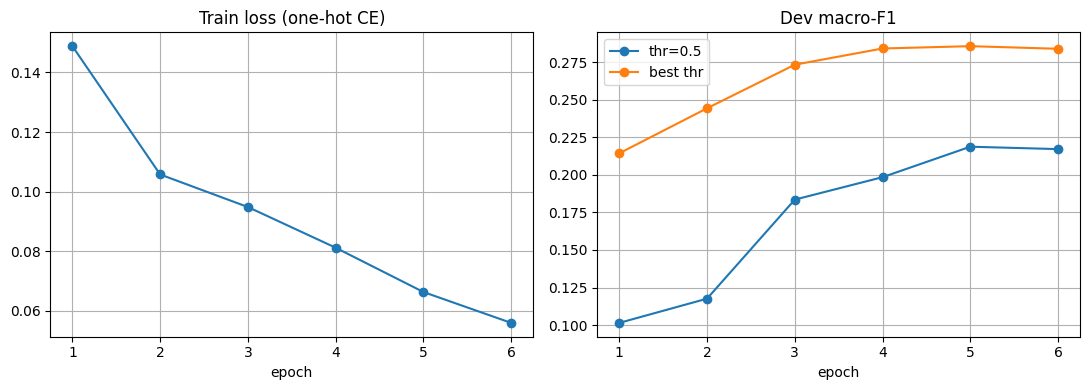

Best epoch: 5 | threshold: 0.15000000000000002
Dev report: {'macro_f1': 0.28565861002302095, 'micro_f1': 0.4194694504880337, 'subset_acc': 0.017778214320793635}


In [16]:
import matplotlib.pyplot as plt
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs_range, history["train_loss"], marker="o"); ax[0].set_title("Train loss (one-hot CE)"); ax[0].set_xlabel("epoch"); ax[0].grid(True)
ax[1].plot(epochs_range, history["dev_macro_f1_thr0.5"], marker="o", label="best_thr_val=0.5")
ax[1].plot(epochs_range, history["dev_macro_f1_best"], marker="o", label="best best_thr_val"); ax[1].set_title("Dev macro-F1"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig(os.path.join(output_dir, "phase5_lorma_curves.png"), dpi=150); plt.show()

checkpoint = torch.load(best_checkpoint_path, map_location="cpu")
model.load_state_dict(checkpoint, strict=False)
threshold = best["best_thr_val"]
print("Best epoch:", best["epoch"], "| threshold:", threshold)
print("Dev report:", f1_report(val_labels, decode(best["val_probs"], threshold)))

In [17]:
test_probs = predict_probs(model, test_tokens)
test_preds = decode(test_probs, threshold)

predictions = []
for rec, row in zip(test_data, test_preds):
    statute_ids = sorted({int(statute_ids_list[j]) for j in np.where(row)[0]})
    predictions.append({"id": rec["id"], "pred": statute_ids})

assert len(predictions) == len(test_data)
assert all(isinstance(x, int) for p in predictions for x in p["pred"])
assert all(len(set(p["pred"])) == len(p["pred"]) and len(p["pred"]) >= 1 for p in predictions)
assert set(p["id"] for p in predictions) == set(r["id"] for r in test_data)
print(f"avg predicted statutes / doc: {np.mean([len(p['pred']) for p in predictions]):.2f}  (train avg {train_labels.sum(1).mean():.2f})")

with open(prediction_output_path, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False)
with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(prediction_output_path, arcname="prediction.json")

print("Wrote", prediction_output_path)
print("Codabench submission:", submission_zip_path)
print(predictions[:2])

avg predicted statutes / doc: 5.83  (train avg 3.70)
Wrote /kaggle/working/cs781_phase5_lorma/prediction.json
Codabench submission: /kaggle/working/cs781_phase5_lorma/submission.zip
[{'id': '100002997', 'pred': [5, 34, 35, 37, 94]}, {'id': '100004477', 'pred': [5, 37, 71, 81, 92, 93, 94]}]
